# Dataset inspection: fake job postings

This notebook starts the project by examining the uploaded archive before any model is trained. It extracts the archive into `data/raw/`, discovers the files and schema, and records the findings. The code does not apply TF-IDF, scaling, encoding, SMOTE, or any other model preprocessing.

Run the inspection cell from top to bottom. If the target column or meaning of its labels is ambiguous, review the printed candidates and label values rather than guessing.

Extracted files:
- data\raw\DataSet.csv (59,068,295 bytes)

Recognized data files:
- data\raw\DataSet.csv [.csv]
Other extracted files:
- None

Main dataset candidate (largest supported data file): data\raw\DataSet.csv

Dataset shape: 17,880 rows x 18 columns

Column names:
['title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent', 'in_balanced_dataset']

Data types:
title                  str
location               str
department             str
salary_range           str
company_profile        str
description            str
requirements           str
benefits               str
telecommuting          str
has_company_logo       str
has_questions          str
employment_type        str
required_experience    str
required_education     str
industry               str
function      

,missing_count,missing_percent
title,0,0.00
location,346,1.94
department,11547,64.58
salary_range,15012,83.96
company_profile,3308,18.50
description,0,0.00
requirements,2689,15.04
benefits,7196,40.25
telecommuting,0,0.00
has_company_logo,0,0.00



Exact duplicate rows: 235
Duplicate non-empty values by text column:


,duplicate_nonempty_values
title,6965
location,14544
department,5051
salary_range,1994
company_profile,12862
description,2785
requirements,3072
benefits,4174
telecommuting,17878
has_company_logo,17878


Duplicate non-empty 'company_profile' values: 12,862
Duplicate non-empty 'description' values: 2,785
Duplicate non-empty 'requirements' values: 3,072
Duplicate non-empty 'benefits' values: 4,174

Target/label candidates discovered from column names:
[('fraudulent', 'fraud/scam/fake-related column name')]
Selected target column: 'fraudulent' (fraud/scam/fake-related column name)
Exact class labels and counts:


,count
class_label,
f,17014
t,866


... (11 outputs left out)

,count
value,
Full-time,11620
<MISSING>,3471
Contract,1524
Part-time,797
Temporary,241
Other,227



Locations — location:


,count
value,
"GB, LND, London",718
"US, NY, New York",658
"US, CA, San Francisco",472
"GR, I, Athens",464
<MISSING>,346
"US, ,",339
"US, TX, Houston",269
"US, IL, Chicago",255
"US, DC, Washington",251


- No column found for companies.

Column groups inferred from observed dtypes and values:
Text (5): ['title', 'company_profile', 'description', 'requirements', 'benefits']
Categorical (8): ['location', 'department', 'salary_range', 'employment_type', 'required_experience', 'required_education', 'industry', 'function']
Numerical (0): []
Boolean (5): ['telecommuting', 'has_company_logo', 'has_questions', 'fraudulent', 'in_balanced_dataset']
Datetime (0): []


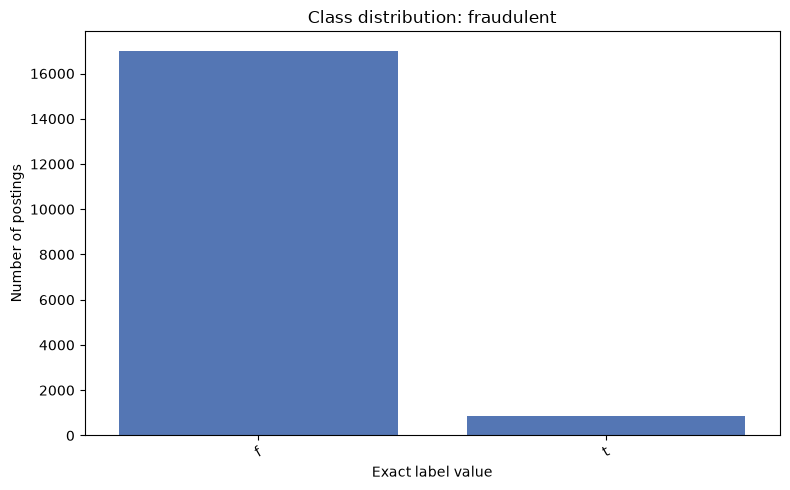

Saved class distribution plot to report\class_distribution.png

Saved inspection report to report\dataset_inspection_report.md
Report size: 8,292 bytes


In [1]:
from pathlib import Path
from zipfile import ZipFile
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# This notebook is stored in fake-job-detector/notebooks, so its parent is the project folder.
PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
elif PROJECT_DIR.name != "fake-job-detector" and (PROJECT_DIR / "fake-job-detector").is_dir():
    PROJECT_DIR = PROJECT_DIR / "fake-job-detector"

RAW_DIR = PROJECT_DIR / "data" / "raw"
REPORT_DIR = PROJECT_DIR / "report"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
for folder in (RAW_DIR, REPORT_DIR, PROCESSED_DIR):
    folder.mkdir(parents=True, exist_ok=True)

archive_path = PROJECT_DIR.parent / "archive.zip"
if not archive_path.is_file():
    raise FileNotFoundError(f"Expected the uploaded archive at: {archive_path}")

# Check each member stays inside data/raw before extraction.
with ZipFile(archive_path) as archive:
    for member in archive.infolist():
        destination = (RAW_DIR / member.filename).resolve()
        if destination != RAW_DIR.resolve() and RAW_DIR.resolve() not in destination.parents:
            raise ValueError(f"Archive member would extract outside data/raw: {member.filename}")
    archive.extractall(RAW_DIR)

all_files = sorted(path for path in RAW_DIR.rglob("*") if path.is_file())
print("Extracted files:")
for path in all_files:
    print(f"- {path.relative_to(PROJECT_DIR)} ({path.stat().st_size:,} bytes)")

supported_extensions = {".csv", ".tsv", ".xlsx", ".xls", ".json", ".jsonl", ".ndjson"}
data_files = [path for path in all_files if path.suffix.lower() in supported_extensions]
other_files = [path for path in all_files if path.suffix.lower() not in supported_extensions]
print("\nRecognized data files:")
for path in data_files:
    print(f"- {path.relative_to(PROJECT_DIR)} [{path.suffix.lower()}]")
print("Other extracted files:")
print("\n".join(f"- {p.relative_to(PROJECT_DIR)}" for p in other_files) if other_files else "- None")
if not data_files:
    raise FileNotFoundError("No supported CSV, TSV, Excel, or JSON data file was found in the archive.")

# If there are multiple supported files, select the largest as the main candidate and show the choice.
main_file = max(data_files, key=lambda path: path.stat().st_size)
print(f"\nMain dataset candidate (largest supported data file): {main_file.relative_to(PROJECT_DIR)}")
suffix = main_file.suffix.lower()
if suffix == ".csv":
    df = pd.read_csv(main_file, low_memory=False)
elif suffix == ".tsv":
    df = pd.read_csv(main_file, sep="\t", low_memory=False)
elif suffix in {".xlsx", ".xls"}:
    df = pd.read_excel(main_file)
elif suffix in {".jsonl", ".ndjson"}:
    df = pd.read_json(main_file, lines=True)
else:
    df = pd.read_json(main_file)

print(f"\nDataset shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes.to_string())

missing_counts = df.isna().sum()
missing_percent = (missing_counts / max(len(df), 1) * 100).round(2)
missing_table = pd.DataFrame({"missing_count": missing_counts, "missing_percent": missing_percent})
print("\nMissing values by column:")
display(missing_table)

duplicate_rows = int(df.duplicated().sum())
print(f"\nExact duplicate rows: {duplicate_rows:,}")
text_columns = [column for column in df.columns if pd.api.types.is_object_dtype(df[column]) or pd.api.types.is_string_dtype(df[column])]
text_duplicate_counts = {}
for column in text_columns:
    nonempty = df[column].dropna().astype(str).str.strip()
    nonempty = nonempty[nonempty.ne("")]
    text_duplicate_counts[column] = int(nonempty.duplicated().sum())
print("Duplicate non-empty values by text column:")
display(pd.Series(text_duplicate_counts, name="duplicate_nonempty_values").to_frame())
description_columns = [column for column in df.columns if re.search(r"description|requirement|benefit|company.?profile|summary|details", str(column), re.I)]
for column in description_columns:
    nonempty = df[column].dropna().astype(str).str.strip()
    nonempty = nonempty[nonempty.ne("")]
    print(f"Duplicate non-empty {column!r} values: {int(nonempty.duplicated().sum()):,}")

# Find likely label names from the actual schema. Fraud/scam/fake-specific names rank highest.
def normalize_name(value):
    return re.sub(r"[^a-z0-9]+", "_", str(value).strip().lower()).strip("_")

strong_label_terms = ("fraud", "fraudulent", "scam", "fake", "spam", "deceptive")
generic_label_terms = ("label", "target", "class", "ground_truth", "is_legitimate", "legitimate")
label_candidates = []
for column in df.columns:
    normalized = normalize_name(column)
    if any(term in normalized for term in strong_label_terms):
        label_candidates.append((column, "fraud/scam/fake-related column name"))
    elif any(term in normalized for term in generic_label_terms):
        label_candidates.append((column, "generic label-related column name"))
print("\nTarget/label candidates discovered from column names:")
print(label_candidates if label_candidates else "No obvious label column found; inspect schema and dataset documentation.")
target_column = label_candidates[0][0] if label_candidates else None
target_reason = label_candidates[0][1] if label_candidates else "No target inferred"
class_counts = None
if target_column is not None:
    class_counts = df[target_column].value_counts(dropna=False)
    print(f"Selected target column: {target_column!r} ({target_reason})")
    print("Exact class labels and counts:")
    display(class_counts.rename_axis("class_label").to_frame("count"))
    print("Class distribution (%):")
    display((class_counts / len(df) * 100).round(2).rename("percent").to_frame())
else:
    print("Target is not identifiable from a target-like column name. No target was guessed.")

# Determine which label values clearly mean fraudulent or legitimate. For common numeric 0/1 labels,
# the code uses 1 as fraud and explicitly records that convention in the report.
fraud_label = None
legitimate_label = None
label_mapping_note = "Label meaning was not confidently inferred; sample groups are not assigned fraud/legitimate names."
if target_column is not None and class_counts is not None:
    labels = [label for label in class_counts.index if not pd.isna(label)]
    def label_kind(label):
        value = str(label).strip().lower()
        if re.search(r"fraud|scam|fake|spam|decept", value):
            return "fraud"
        if re.search(r"legit|genuine|real|authentic|not.?fraud|non.?fraud", value):
            return "legitimate"
        return None
    for label in labels:
        kind = label_kind(label)
        if kind == "fraud":
            fraud_label = label
        elif kind == "legitimate":
            legitimate_label = label
    if fraud_label is not None and legitimate_label is not None:
        label_mapping_note = f"Text labels identify {fraud_label!r} as fraudulent and {legitimate_label!r} as legitimate."
    elif len(labels) == 2 and {str(label).strip().lower() for label in labels} == {"t", "f"}:
        fraud_label = next(label for label in labels if str(label).strip().lower() == "t")
        legitimate_label = next(label for label in labels if str(label).strip().lower() == "f")
        label_mapping_note = "The target column is named fraudulent and its labels are `t`/`f`; these are interpreted as true/fraudulent and false/legitimate respectively."
    elif len(labels) == 2 and {str(label).strip().lower() for label in labels} == {"1", "0"}:
        fraud_label = next(label for label in labels if str(label).strip() == "1")
        legitimate_label = next(label for label in labels if str(label).strip() == "0")
        label_mapping_note = "Binary numeric convention used for sample display only: 1 = fraudulent, 0 = legitimate; verify against the dataset source."
    elif len(labels) == 2 and set(labels) == {False, True}:
        fraud_label, legitimate_label = True, False
        label_mapping_note = "Boolean convention used for sample display only: True = fraudulent, False = legitimate; verify against the dataset source."
    elif fraud_label is not None:
        label_mapping_note = f"Text identifies {fraud_label!r} as fraudulent, but no legitimate label was confidently identified."
    print(f"\nSample label interpretation: {label_mapping_note}")

def show_posting_samples(label, title):
    if target_column is None or label is None:
        print(f"\n{title}: unavailable because the target or label meaning is ambiguous.")
        return
    selected = df.loc[df[target_column].eq(label)].head(5)
    print(f"\n{title} (up to 5 rows; target value = {label!r}):")
    sample_columns = list(dict.fromkeys(([target_column] + [c for c in df.columns if re.search(r"title|company|description|requirement|benefit|location", str(c), re.I)])))
    if not sample_columns:
        sample_columns = list(df.columns[: min(8, len(df.columns))])
    display(selected[sample_columns])

show_posting_samples(legitimate_label, "Sample legitimate postings")
show_posting_samples(fraud_label, "Sample fraudulent postings")
if target_column is not None and (fraud_label is None or legitimate_label is None):
    print("\nBecause label semantics are ambiguous, here are up to 5 examples for each exact class value:")
    sample_columns = list(dict.fromkeys(([target_column] + [c for c in df.columns if re.search(r"title|company|description|requirement|benefit|location", str(c), re.I)])))
    for label in class_counts.index:
        print(f"\nClass {label!r}:")
        display(df.loc[df[target_column].eq(label), sample_columns].head(5))

# Show common values for likely metadata fields when present.
field_patterns = {
    "job titles": r"(^|_)title($|_)|job.?title",
    "industries": r"industry",
    "employment types": r"employment.?type|job.?type",
    "locations": r"location|city|country",
    "companies": r"^(?:company|company_name|employer|employer_name|organization|organization_name)$",
}
top_values = {}
print("\nMost common metadata values (where a matching column exists):")
for display_name, pattern in field_patterns.items():
    matching_columns = [column for column in df.columns if re.search(pattern, str(column), re.I)]
    if matching_columns:
        for column in matching_columns:
            values = df[column].fillna("<MISSING>").astype(str).value_counts().head(10)
            top_values[str(column)] = values
            print(f"\n{display_name.title()} — {column}:")
            display(values.rename_axis("value").to_frame("count"))
    else:
        print(f"- No column found for {display_name}.")

# Categorize columns using their observed dtype and value patterns, without transforming the data.
column_types = {"text": [], "categorical": [], "numerical": [], "boolean": [], "datetime": []}
for column in df.columns:
    series = df[column]
    if pd.api.types.is_bool_dtype(series):
        kind = "boolean"
    elif pd.api.types.is_datetime64_any_dtype(series):
        kind = "datetime"
    elif pd.api.types.is_numeric_dtype(series):
        kind = "numerical"
    elif pd.api.types.is_object_dtype(series) or pd.api.types.is_string_dtype(series):
        nonmissing = series.dropna().astype(str)
        average_length = nonmissing.str.len().mean() if len(nonmissing) else 0
        unique_ratio = series.nunique(dropna=True) / max(series.notna().sum(), 1)
        normalized_values = {value.strip().lower() for value in nonmissing.unique()}
        boolean_values = ({"true", "false"}, {"t", "f"}, {"yes", "no"}, {"1", "0"})
        if len(normalized_values) == 2 and normalized_values in boolean_values:
            kind = "boolean"
        elif average_length >= 40 or re.search(r"description|requirement|benefit|profile|summary", str(column), re.I):
            kind = "text"
        elif unique_ratio <= 0.5 or series.nunique(dropna=True) <= 50:
            kind = "categorical"
        else:
            kind = "text"
    else:
        kind = "categorical"
    column_types[kind].append(str(column))
print("\nColumn groups inferred from observed dtypes and values:")
for kind, columns in column_types.items():
    print(f"{kind.title()} ({len(columns)}): {columns}")

# Draw and save the exact observed class distribution (when a label column exists).
if target_column is not None:
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(x=class_counts.index.astype(str), y=class_counts.values, ax=ax, color="#4472C4")
    ax.set_title(f"Class distribution: {target_column}")
    ax.set_xlabel("Exact label value")
    ax.set_ylabel("Number of postings")
    ax.tick_params(axis="x", rotation=30)
    fig.tight_layout()
    plot_path = REPORT_DIR / "class_distribution.png"
    fig.savefig(plot_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved class distribution plot to {plot_path.relative_to(PROJECT_DIR)}")
else:
    plot_path = None
    print("Class distribution plot not generated because no target column could be identified.")

# Prepare a readable data-quality summary and detailed, leakage-aware next-stage plan.
quality_rows = []
for column in df.columns:
    quality_rows.append({
        "column": str(column),
        "dtype": str(df[column].dtype),
        "missing_count": int(missing_counts[column]),
        "missing_percent": float(missing_percent[column]),
        "unique_nonmissing": int(df[column].nunique(dropna=True)),
        "duplicate_nonempty_text_values": text_duplicate_counts.get(column, "not a text column"),
    })

def markdown_table(frame):
    """Format a small pandas table as Markdown without extra dependencies."""
    values = frame.fillna("").astype(str).apply(lambda column: column.str.replace("|", r"\|", regex=False))
    headers = [str(column) for column in values.columns]
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join("---" for _ in headers) + " |"]
    lines.extend("| " + " | ".join(row) + " |" for row in values.to_numpy().tolist())
    return "\n".join(lines)

quality_table = pd.DataFrame(quality_rows)
quality_markdown = markdown_table(quality_table)
if target_column is not None:
    class_summary = pd.DataFrame({"class_label": class_counts.index.astype(str), "count": class_counts.values, "percent": (class_counts.values / len(df) * 100).round(2)})
    class_markdown = markdown_table(class_summary)
else:
    class_markdown = "No target/label column could be confidently identified from the column names."
top_markdown_parts = []
for column, values in top_values.items():
    top_markdown_parts.append(f"### {column}\n\n" + markdown_table(values.rename_axis("value").reset_index(name="count")))
top_markdown = "\n\n".join(top_markdown_parts) if top_markdown_parts else "No matching metadata columns were found."

next_stage_plan = """
## Plan for the next project stages (not run in this notebook)

1. **Data cleaning:** Confirm the target label meaning with the dataset source; remove exact duplicate rows with a documented rule; inspect duplicate postings/text for repeated or syndicated entries; normalize blank strings to missing values; review inconsistent categories and impossible values; investigate the provenance of `in_balanced_dataset` and exclude it from predictors unless it is available at prediction time and is not derived from sampling or labels; keep a copy of the raw data unchanged.
2. **Text preprocessing:** Combine available posting text fields (such as title, company profile, description, requirements, and benefits) only after confirming the schema. Preserve useful tokens, normalize whitespace, and avoid removing scam-relevant URLs, contact details, amounts, or urgent terms before indicator features are created. Fit any learned text transforms on training data only.
3. **Feature engineering:** Add description/requirements length, URL/email/phone counts, exclamation marks, missing-company-profile indicator, urgent-language, fee-request, and easy-money phrase indicators. Use only fields present in this dataset and document the rules. Encode categorical metadata and derive numerical features with transformers fitted on training data.
4. **Train-test splitting:** Define the fraud target after its labels are verified. Split rows into train and held-out test sets with `train_test_split(..., stratify=y, random_state=...)` before fitting TF-IDF, imputers, scalers, encoders, feature selection, resampling, or other learned transformations. Consider grouping exact/near-duplicate postings before splitting to reduce leakage.
5. **Model training:** Build a scikit-learn preprocessing/model pipeline that combines TF-IDF text with encoded categorical and numerical features. Compare a simple baseline with a hybrid classifier and XGBoost where suitable. Keep all fitted transforms inside the training pipeline; do not train a model during the inspection stage.
6. **Class-imbalance handling:** First evaluate class weights and threshold adjustment. If SMOTE or another resampler is justified, apply it only to the training fold (preferably inside an imbalanced-learn pipeline and cross-validation), never before the train-test split and never to validation/test data.
7. **Model evaluation:** Use a stratified validation strategy on training data for model/threshold selection, then evaluate once on the held-out test set. Report fraud-class precision, recall, F1-score, ROC-AUC, PR-AUC, and a confusion matrix, alongside class counts and accuracy as a secondary metric. State the positive class explicitly.
8. **Explainability:** Explain global and individual predictions with suitable feature importance or SHAP methods after model selection. Ensure explanations align with the fitted pipeline and distinguish association from causation; avoid exposing sensitive personal data in reports.
9. **Streamlit application:** Save the selected model and preprocessing pipeline with Joblib. Build `app.py` to accept the fields available in the dataset, validate inputs, show a fraud risk score and clear limitations, and avoid claiming certainty. Load the same saved preprocessing/model pipeline used during evaluation.
"""

report_lines = [
    "# Dataset Inspection Report",
    "",
    "> Generated by `notebooks/01_dataset_inspection.ipynb`. No model was trained and no complete-dataset preprocessing was performed.",
    "",
    "## Archive and files",
    "",
    f"- Archive: `{archive_path.name}`",
    f"- Main dataset selected: `{main_file.relative_to(PROJECT_DIR)}` (largest supported data file)",
    f"- Shape: **{df.shape[0]:,} rows x {df.shape[1]:,} columns**",
    "- Extracted files: " + (", ".join(f"`{p.relative_to(PROJECT_DIR)}`" for p in all_files) if all_files else "none"),
    "",
    "## Target and class distribution",
    "",
    f"- Target column: `{target_column}`" if target_column is not None else "- Target column: **not confidently identified**",
    f"- Identification reason: {target_reason}",
    f"- Sample label interpretation: {label_mapping_note}",
    "",
    class_markdown,
    "",
    "## Schema",
    "",
    "### Column names",
    "",
    ", ".join(f"`{column}`" for column in df.columns),
    "",
    "### Pandas data types",
    "",
    "```text",
    df.dtypes.to_string(),
    "```",
    "",
    "### Inferred feature groups",
    "",
    *[f"- **{kind.title()}:** {', '.join(columns) if columns else 'None'}" for kind, columns in column_types.items()],
    "",
    "## Data-quality checks",
    "",
    f"- Exact duplicate rows: **{duplicate_rows:,}**",
    "- Duplicate non-empty text values are summarized per column below. These are counts of repeated values after the first occurrence, not proof that two full postings are duplicates.",
    "",
    quality_markdown,
    "",
    "## Most common metadata values",
    "",
    top_markdown,
    "",
    "## Class distribution plot",
    "",
    f"Plot saved to `{plot_path.relative_to(PROJECT_DIR)}`." if plot_path is not None else "No plot generated because no target column was identified.",
    "",
    next_stage_plan.strip(),
    "",
    "## Inspection boundaries",
    "",
    "This report documents observed values, missingness, duplicates, and schema. It does not clean or alter the raw dataset, fit a vectorizer/encoder/scaler, apply SMOTE, split the data, or train/evaluate a model.",
]

report_path = REPORT_DIR / "dataset_inspection_report.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print(f"\nSaved inspection report to {report_path.relative_to(PROJECT_DIR)}")
print(f"Report size: {report_path.stat().st_size:,} bytes")

## What happens next

The generated report contains an evidence-based schema and a detailed plan for cleaning, feature engineering, stratified splitting, modeling, imbalance handling, evaluation, explainability, and the Streamlit interface. Stop here for review and confirmation before implementing those stages.